# Model 04: Fine-Tuned BERT + WordNet Features

## 
This notebook presents the submission-style summary for our fine-tuned BERT + WordNet feature fusion method. It follows the same repository style as the other team notebooks and reports the saved training and evaluation outputs without retraining the model.


## 1. Comparable Setup

- Seed: `42`
- Split: `train/val/test = 8/1/1` from the shared HC3 WordNet split
- Labels: `0 = human`, `1 = AI-generated`
- Backbone: `bert-base-uncased`
- Fusion input: `[CLS]` embedding + 4 normalized WordNet features
- Saved run used here: `formal_main`
- Training budget: `batch_size=8`, `epochs=2`, `max_length=128`, `lr=2e-5`, `weight_decay=0.01`
- Metrics: Accuracy, Precision, Recall, F1


In [1]:
from pathlib import Path
import ast
import json

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        if hasattr(obj, 'data') and hasattr(obj, 'columns'):
            print(obj.to_string(index=False))
        elif hasattr(obj, 'to_string'):
            print(obj.to_string())
        else:
            print(obj)

BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name != 'model04_finetuned_model':
    BASE_DIR = BASE_DIR / 'comp6713-ass2' / 'model04_finetuned_model'

RESULTS_DIR = BASE_DIR / 'results'

FILES = {
    'model': BASE_DIR / 'bert_wordnet_model.py',
    'train': BASE_DIR / 'train_bert_wordnet.py',
    'eval': BASE_DIR / 'eval_bert_wordnet.py',
    'features': BASE_DIR / 'wordnet_features.py',
    'splits': BASE_DIR / 'data_splits.py',
    'metrics': RESULTS_DIR / 'metrics.json',
    'test_metrics': RESULTS_DIR / 'test_metrics.json',
    'epoch_metrics': RESULTS_DIR / 'epoch_metrics.json',
    'run_info': RESULTS_DIR / 'run_info.json',
    'val_predictions': RESULTS_DIR / 'val_predictions.csv',
    'test_predictions': RESULTS_DIR / 'test_predictions.csv',
}

for name, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(f'Missing required file for notebook section {name}: {path}')

print('Notebook base directory:', BASE_DIR)
print('Results directory:', RESULTS_DIR)


Notebook base directory: C:\Users\11630\Desktop\6713\comp6713-ass2\model04_finetuned_model
Results directory: C:\Users\11630\Desktop\6713\comp6713-ass2\model04_finetuned_model\results


## 2. Method Overview

This method extends standard BERT fine-tuning by combining a contextual text representation with compact lexical-semantic signals derived from WordNet. The main idea is to let BERT capture sentence-level meaning while the WordNet features provide additional information about lexical coverage, semantic ambiguity, and hierarchical depth.

The implementation is kept lightweight and repository-friendly: WordNet features are generated offline, standardised during training, concatenated with the BERT `[CLS]` representation, and passed through a small classification head for binary prediction.


## 3. WordNet Feature Summary


In [2]:
feature_source = FILES['features'].read_text(encoding='utf-8')
feature_tree = ast.parse(feature_source)

feature_columns = []
for node in feature_tree.body:
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if isinstance(target, ast.Name) and target.id == 'FEATURE_COLUMNS':
                feature_columns = ast.literal_eval(node.value)

feature_descriptions = {
    'wn_avg_synset_count': 'Average number of WordNet synsets for content-word lemmas in the text.',
    'wn_avg_synonym_count': 'Average number of WordNet synonyms associated with the matched synsets.',
    'wn_coverage_ratio': 'Proportion of content words that receive at least one WordNet synset match.',
    'wn_avg_hypernym_depth': 'Average hypernym-tree depth for covered content words, used as a semantic-specificity signal.',
}

feature_pipeline = pd.DataFrame(
    {
        'Feature': feature_columns,
        'Meaning': [feature_descriptions[col] for col in feature_columns],
    }
)

print('WordNet features are extracted from lemmatised content words only (NN, VB, JJ, RB),')
print('which keeps the feature set focused on semantically meaningful tokens.')
display(feature_pipeline)


WordNet features are extracted from lemmatised content words only (NN, VB, JJ, RB),
which keeps the feature set focused on semantically meaningful tokens.


Feature,Meaning
wn_avg_synset_count,Average number of WordNet synsets for content-word lemmas in the text.
wn_avg_synonym_count,Average number of WordNet synonyms associated with the matched synsets.
wn_coverage_ratio,Proportion of content words that receive at least one WordNet synset match.
wn_avg_hypernym_depth,"Average hypernym-tree depth for covered content words, used as a semantic-specificity signal."


## 4. Model Architecture

Fusion used in the implementation: `[CLS] embedding + WordNet feature vector -> classifier`.


In [3]:
model_source = FILES['model'].read_text(encoding='utf-8')
train_source = FILES['train'].read_text(encoding='utf-8')

architecture_summary = pd.DataFrame(
    [
        ('Encoder', 'BERT base uncased loaded with `AutoModel.from_pretrained(...)`'),
        ('Text representation', 'Final-layer `[CLS]` token embedding (`last_hidden_state[:, 0]`)'),
        ('Extra input', '4 WordNet features concatenated to the contextual text representation'),
        ('Regularisation', 'Dropout applied before fusion and again inside the classifier head'),
        ('Classifier head', 'Linear(hidden+4 -> hidden/2) -> ReLU -> Dropout -> Linear(hidden/2 -> 2)'),
        ('Prediction target', 'Binary classification: human vs AI-generated text'),
    ],
    columns=['Component', 'Details']
)

display(architecture_summary)
print('Model file:', FILES['model'].name)
print('Training script:', FILES['train'].name)


Model file: bert_wordnet_model.py
Training script: train_bert_wordnet.py


Component,Details
Encoder,BERT base uncased loaded with `AutoModel.from_pretrained(...)`
Text representation,"Final-layer `[CLS]` token embedding (`last_hidden_state[:, 0]`)"
Extra input,4 WordNet features concatenated to the contextual text representation
Regularisation,Dropout applied before fusion and again inside the classifier head
Classifier head,Linear(hidden+4 -> hidden/2) -> ReLU -> Dropout -> Linear(hidden/2 -> 2)
Prediction target,Binary classification: human vs AI-generated text


## 5. Core Implementation Blocks

The notebook below shows the main code blocks used in the saved method so the presentation remains closer to the existing team notebooks and not just a thin summary.


In [4]:
def extract_block(text, start_marker, end_marker=None):
    start = text.index(start_marker)
    end = text.index(end_marker, start) if end_marker else len(text)
    return text[start:end].strip()

print('BertWordNetClassifier')
print('-' * 80)
print(extract_block(model_source, 'class BertWordNetClassifier', 'def forward'))
print()
print('forward(...)')
print('-' * 80)
print(extract_block(model_source, 'def forward', 'result = {"logits": logits}'))
print('result = {"logits": logits}')
print('if labels is not None:')
print('    loss = nn.CrossEntropyLoss()(logits, labels)')
print('    result["loss"] = loss')
print('return result')
print()
print('compute_wordnet_features(...)')
print('-' * 80)
print(extract_block(feature_source, 'def compute_wordnet_features', 'def load_processed_dataset'))
print()
print('evaluate_model(...) and artifact outputs')
print('-' * 80)
print(extract_block(train_source, 'def evaluate_model', 'def save_training_artifacts'))


BertWordNetClassifier
--------------------------------------------------------------------------------
class BertWordNetClassifier(nn.Module):
    """Binary classifier that fuses a BERT text representation with four normalized WordNet features."""

    def __init__(self, config: BertWordNetConfig) -> None:
        super().__init__()
        self.config = config
        self.bert = AutoModel.from_pretrained(config.model_name)
        hidden_size = self.bert.config.hidden_size

        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size + config.wordnet_feature_dim, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(config.dropout),
            nn.Linear(hidden_size // 2, config.num_labels),
        )

forward(...)
--------------------------------------------------------------------------------
def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        wordnet_fea

## 6. Training Configuration

This notebook reports the saved `formal_main` run. It does not retrain the model.


In [5]:
run_info = json.loads(FILES['run_info'].read_text(encoding='utf-8'))
val_metrics = json.loads(FILES['metrics'].read_text(encoding='utf-8'))
test_metrics = json.loads(FILES['test_metrics'].read_text(encoding='utf-8'))
epoch_metrics = pd.DataFrame(json.loads(FILES['epoch_metrics'].read_text(encoding='utf-8')))

split_source = FILES['splits'].read_text(encoding='utf-8')
split_tree = ast.parse(split_source)
split_constants = {}
for node in split_tree.body:
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if isinstance(target, ast.Name) and target.id in {'RANDOM_SEED', 'TRAIN_RATIO', 'VAL_RATIO', 'TEST_RATIO'}:
                split_constants[target.id] = ast.literal_eval(node.value)

training_config = pd.DataFrame(
    [
        ('Run name', run_info['run_name']),
        ('Mode', run_info['mode']),
        ('Device used for saved run', run_info['device']),
        ('Random seed', split_constants.get('RANDOM_SEED', 42)),
        ('Data split', f"{int(split_constants.get('TRAIN_RATIO', 0.8)*10)}/{int(split_constants.get('VAL_RATIO', 0.1)*10)}/{int(split_constants.get('TEST_RATIO', 0.1)*10)}"),
        ('Completed epochs', run_info['completed_epochs']),
        ('Batch size', run_info['batch_size']),
        ('Max length', run_info['max_length']),
        ('Learning rate', '2e-5'),
        ('Weight decay', '0.01'),
        ('Validation split file', Path(run_info['val_path']).name),
        ('Base model path', run_info['model_path']),
    ],
    columns=['Setting', 'Value']
)

display(training_config)
display(epoch_metrics)


Setting,Value
Run name,formal_main
Mode,formal
Device used for saved run,cuda
Random seed,42
Data split,8/1/1
Completed epochs,2
Batch size,8
Max length,128
Learning rate,2e-5
Weight decay,0.01


accuracy,precision,recall,f1,train_loss,epoch
0.990870,0.972484,0.999256,0.985688,0.033376,1
0.992743,0.979547,0.997768,0.988574,0.011740,2


## 7. Final Validation and Test Results

The table below reports the saved validation and test scores from the local result artifacts.


In [6]:
validation_metrics_display = pd.DataFrame([val_metrics]).round(4)
test_metrics_display = pd.DataFrame([test_metrics]).round(4)

print('Validation metrics')
display(validation_metrics_display)
print('Test metrics')
display(test_metrics_display)

best_epoch = epoch_metrics.sort_values('f1', ascending=False).iloc[0]
print('Best validation epoch:', int(best_epoch['epoch']))
print('Validation train loss at best epoch:', f"{best_epoch['train_loss']:.6f}")


Validation metrics
Test metrics
Best validation epoch: 2
Validation train loss at best epoch: 0.011740


accuracy,precision,recall,f1,train_loss,epoch
0.9927,0.9795,0.9978,0.9886,0.0117,2


accuracy,precision,recall,f1
0.9967,0.9911,0.9985,0.9948


## 8. Small Preview of Prediction Outputs

To keep the notebook submission-friendly, only a small preview of the saved prediction files is shown.


In [7]:
val_predictions = pd.read_csv(FILES['val_predictions'])
test_predictions = pd.read_csv(FILES['test_predictions'])

prediction_summary = pd.DataFrame(
    [
        {
            'Split': 'Validation',
            'Rows': len(val_predictions),
            'Correct': int((val_predictions['label'] == val_predictions['prediction']).sum()),
            'Predicted human (0)': int((val_predictions['prediction'] == 0).sum()),
            'Predicted AI (1)': int((val_predictions['prediction'] == 1).sum()),
        },
        {
            'Split': 'Test',
            'Rows': len(test_predictions),
            'Correct': int((test_predictions['label'] == test_predictions['prediction']).sum()),
            'Predicted human (0)': int((test_predictions['prediction'] == 0).sum()),
            'Predicted AI (1)': int((test_predictions['prediction'] == 1).sum()),
        },
    ]
)

display(prediction_summary)
display(val_predictions.head(5))
display(test_predictions.head(5))


Split,Rows,Correct,Predicted human (0),Predicted AI (1)
Validation,8543,8481,5805,2738
Test,8544,8516,5835,2709


example_id,label,prediction
hc3_ex_000002,0,0
hc3_ex_000012,0,0
hc3_ex_000035,1,1
hc3_ex_000037,0,0
hc3_ex_000064,0,0


example_id,label,prediction
hc3_ex_000013,0,0
hc3_ex_000016,0,0
hc3_ex_000019,1,1
hc3_ex_000021,0,0
hc3_ex_000023,1,1


## 9. Confusion Matrix

The confusion matrix below summarises the saved test predictions using the available true and predicted labels.


<cell 8>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


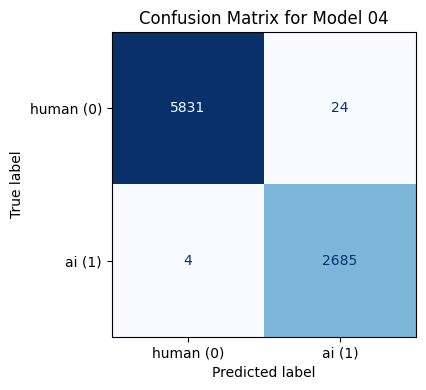

In [8]:
required_columns = {'label', 'prediction'}
missing_columns = required_columns.difference(test_predictions.columns)
if missing_columns:
    print(f'Confusion matrix not supported. Missing columns: {sorted(missing_columns)}')
else:
    cm = confusion_matrix(test_predictions['label'], test_predictions['prediction'])
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['human (0)', 'ai (1)'])
    disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title('Confusion Matrix for Model 04')
    plt.tight_layout()
    plt.show()


## 10. Evaluation Metrics Bar Chart

The bar chart below visualises the saved test-set accuracy, precision, recall, and F1 scores.


<cell 9>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


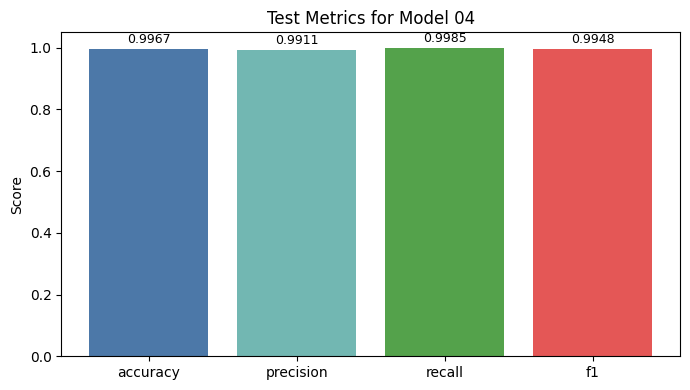

In [9]:
metric_names = ['accuracy', 'precision', 'recall', 'f1']
metric_values = [test_metrics[name] for name in metric_names]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(metric_names, metric_values, color=['#4C78A8', '#72B7B2', '#54A24B', '#E45756'])
ax.set_ylim(0.0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Test Metrics for Model 04')

for bar, value in zip(bars, metric_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f'{value:.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


## 11. Short Conclusion

This fine-tuned BERT + WordNet method achieved strong performance on both validation and test data while staying close to the shared team setup. The result suggests that compact WordNet-based lexical-semantic features can complement contextual transformer representations and slightly strengthen a standard BERT detector without turning the notebook into a long experimental workflow.
